<a href="https://colab.research.google.com/github/BERUK-GGG/Brain-Eye-Arm/blob/main/industrial_ai_model_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Sat Sep 19 21:23:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 94.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.8 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [3]:

from roboflow import Roboflow
rf = Roboflow(api_key="1a2GsZK337hrHv12fS4V")
project = rf.workspace("beruk-gebru").project("industrial-ai-lzr8f")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to industrial-ai-1 in yolov8:: 100%|██████████| 147/147 [00:00<00:00, 4472.71it/s]


In [4]:
print("Dataset downloaded to:", dataset.location)

Dataset downloaded to: /content/industrial-ai-1


In [5]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 9.2 MB/s eta 0:00:00


In [6]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [7]:
MODELS_TO_TRY = ["yolov8n.pt", "yolo26n.pt"]


In [8]:
trained_models = {}

for weights in MODELS_TO_TRY:
    print(f"\n{'='*60}\nTraining {weights}\n{'='*60}")
    model = YOLO(weights)
    run_name = weights.replace(".pt", "")
    model.train(
        data=f"{dataset.location}/data.yaml",
        epochs=100,
        imgsz=640,
        batch=16,
        patience=20,       # stop early if validation stops improving
        project="dobot_shapes",
        name=run_name,
    )
    trained_models[weights] = model



Training yolov8n.pt
Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/industrial-ai-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms

In [9]:
comparison = []

for weights, model in trained_models.items():
    metrics = model.val()
    comparison.append({
        "model": weights,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "precision": metrics.box.mp,
        "recall": metrics.box.mr,
    })


Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3795.6±1296.1 MB/s, size: 244.4 KB)
val: Scanning /content/industrial-ai-1/valid/labels.cache... 7 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7/7 1.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.4it/s 0.2s
                   all          7         13      0.967          1      0.995      0.995
                Circle          1          1      0.921          1      0.995      0.995
             Rectangle          6          8       0.99          1      0.995      0.995
              Triangle          2          4       0.99          1      0.995      0.995
Speed: 0.3ms preprocess, 6.2ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 

In [10]:

print(f"\n{'Model':<15}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}")
for row in comparison:
    print(f"{row['model']:<15}{row['mAP50']:<10.3f}{row['mAP50-95']:<12.3f}"
          f"{row['precision']:<12.3f}{row['recall']:<10.3f}")




Model          mAP50     mAP50-95    Precision   Recall    
yolov8n.pt     0.995     0.995       0.967       1.000     
yolo26n.pt     0.995     0.995       0.980       1.000     


In [11]:
import time
import glob

In [12]:

val_images = glob.glob(f"{dataset.location}/valid/images/*.jpg")
test_img = val_images[0]

print(f"\n{'Model':<15}{'Inference time (Colab GPU)':<30}")
for weights, model in trained_models.items():
    model.predict(test_img)  # warmup -- first inference is always slower
    start = time.time()
    model.predict(test_img)
    elapsed = time.time() - start
    print(f"{weights:<15}{elapsed:.3f}s")




Model          Inference time (Colab GPU)    

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_141541_780529_jpg.rf.5542d7a5d2498076298f102ea9698010.jpg: 544x640 1 Rectangle, 6.9ms
Speed: 2.5ms preprocess, 6.9ms inference, 1.4ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_141541_780529_jpg.rf.5542d7a5d2498076298f102ea9698010.jpg: 544x640 1 Rectangle, 7.0ms
Speed: 2.2ms preprocess, 7.0ms inference, 1.3ms postprocess per image at shape (1, 3, 544, 640)
yolov8n.pt     0.036s

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_141541_780529_jpg.rf.5542d7a5d2498076298f102ea9698010.jpg: 544x640 1 Rectangle, 8.3ms
Speed: 2.4ms preprocess, 8.3ms inference, 1.1ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_141541_780529_jpg.rf.5542d7a5d2498076298f102ea9698010.jpg: 544x640 1 Rectangle, 8.5ms
Speed: 2.1ms preprocess, 8.5ms inference, 1.3ms pos


image 1/1 /content/industrial-ai-1/valid/images/img_20260919_140647_306586_jpg.rf.590238973ac8927cf1df34f57ae4cc17.jpg: 544x640 2 Rectangles, 7.1ms
Speed: 2.2ms preprocess, 7.1ms inference, 1.3ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_140348_811256_jpg.rf.a2ce8d252d5f6b3910acfe9c58743818.jpg: 544x640 1 Circle, 1 Rectangle, 2 Triangles, 15.3ms
Speed: 4.9ms preprocess, 15.3ms inference, 4.1ms postprocess per image at shape (1, 3, 544, 640)


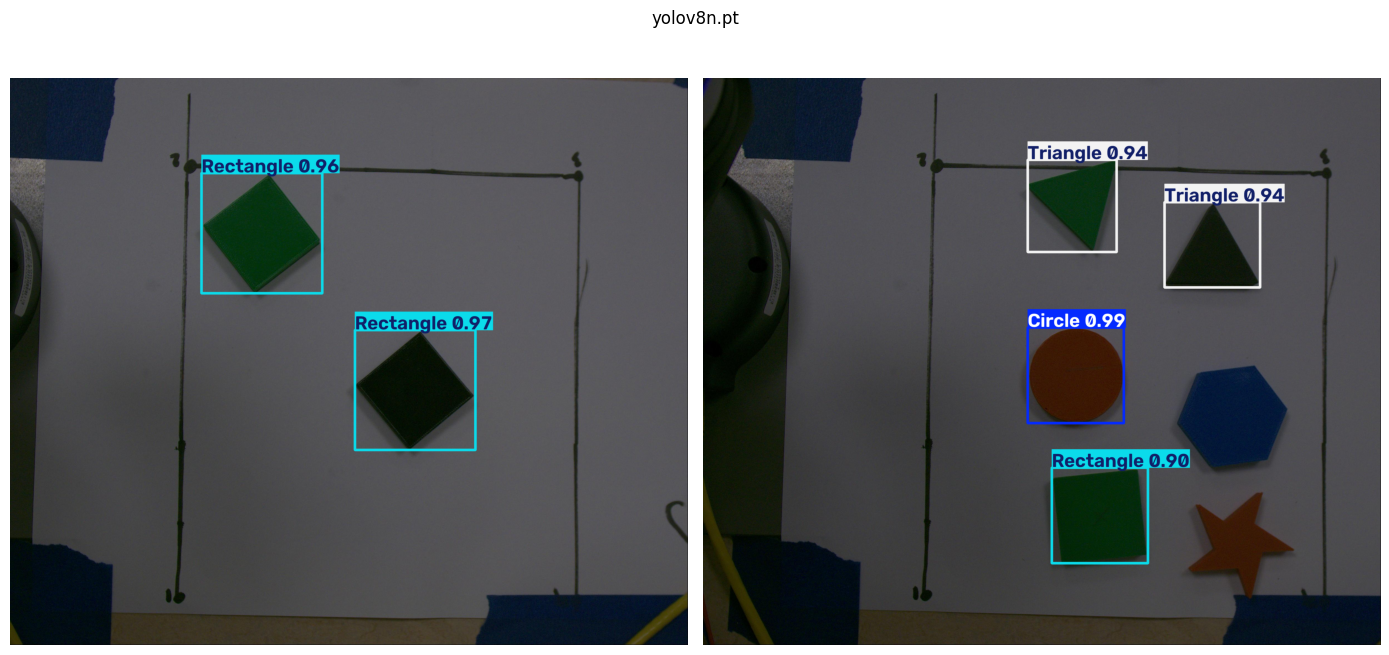


image 1/1 /content/industrial-ai-1/valid/images/img_20260919_140647_306586_jpg.rf.590238973ac8927cf1df34f57ae4cc17.jpg: 544x640 2 Rectangles, 12.2ms
Speed: 3.9ms preprocess, 12.2ms inference, 1.6ms postprocess per image at shape (1, 3, 544, 640)

image 1/1 /content/industrial-ai-1/valid/images/img_20260919_140348_811256_jpg.rf.a2ce8d252d5f6b3910acfe9c58743818.jpg: 544x640 1 Circle, 1 Rectangle, 2 Triangles, 14.0ms
Speed: 5.2ms preprocess, 14.0ms inference, 1.7ms postprocess per image at shape (1, 3, 544, 640)


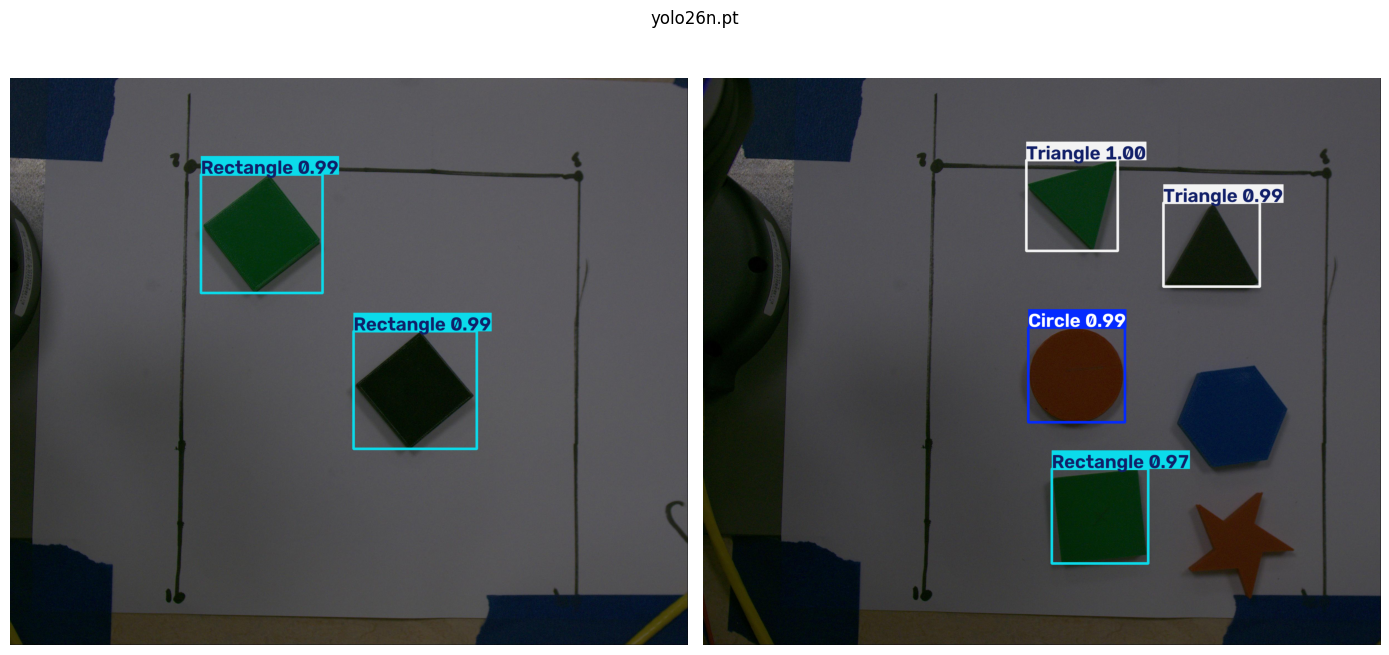

In [17]:
import matplotlib.pyplot as plt

sample_images = val_images[4:6]

for weights, model in trained_models.items():
    fig, axes = plt.subplots(1, len(sample_images), figsize=(14, 7))
    if len(sample_images) == 1:
        axes = [axes]
    fig.suptitle(weights)
    for ax, img_path in zip(axes, sample_images):
        result = model.predict(img_path, conf=0.4)[0]
        annotated_bgr = result.plot()
        ax.imshow(annotated_bgr[..., ::-1])  # BGR -> RGB for matplotlib
        ax.axis("off")
    plt.tight_layout()
    plt.show()


Test-set evaluation: yolov8n.pt
Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2918.5±289.5 MB/s, size: 261.2 KB)
val: Scanning /content/industrial-ai-1/test/labels.cache... 7 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7/7 2.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.2it/s 0.2s
                   all          7         28      0.984          1      0.995      0.984
                Circle          4          4       0.97          1      0.995      0.995
             Rectangle          7          9      0.985          1      0.995      0.978
              Triangle          6         15      0.997          1      0.995      0.978
Speed: 0.3ms preprocess, 5.3ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /conte

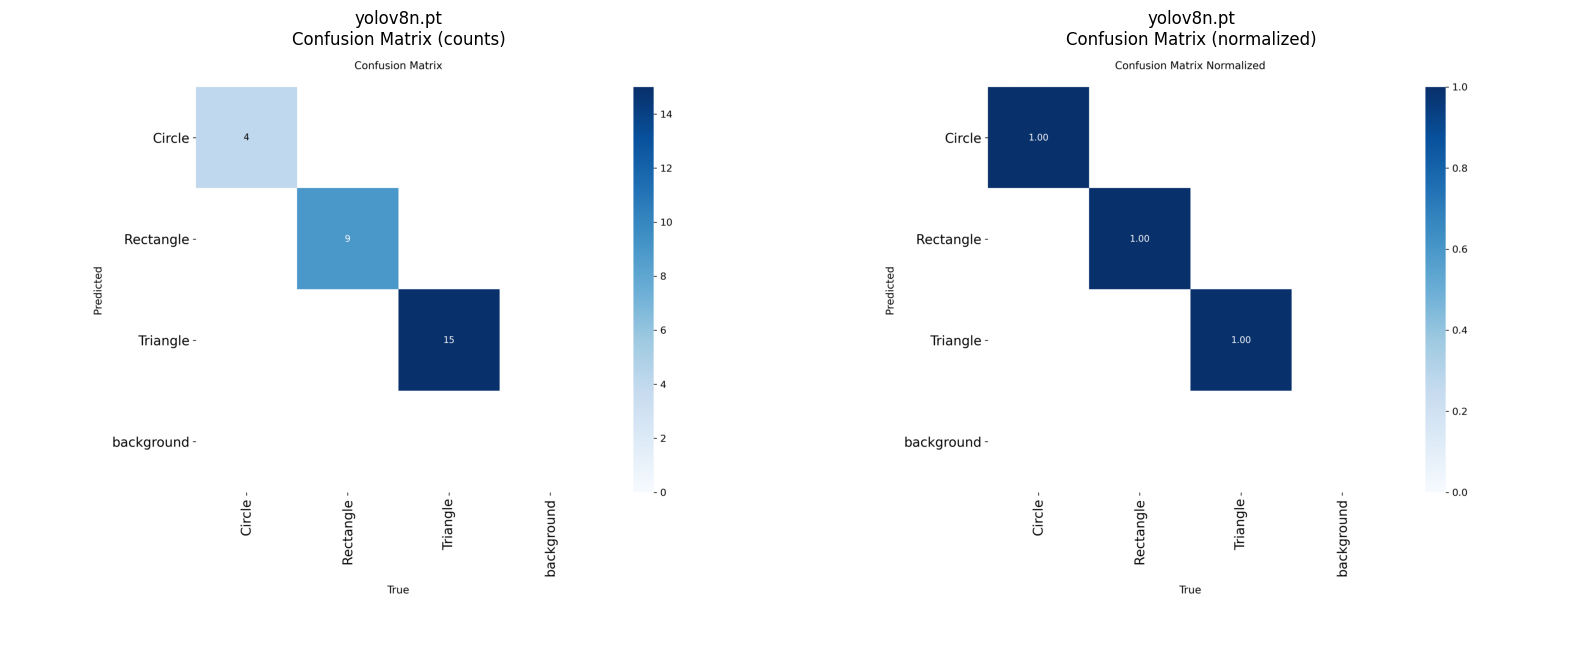

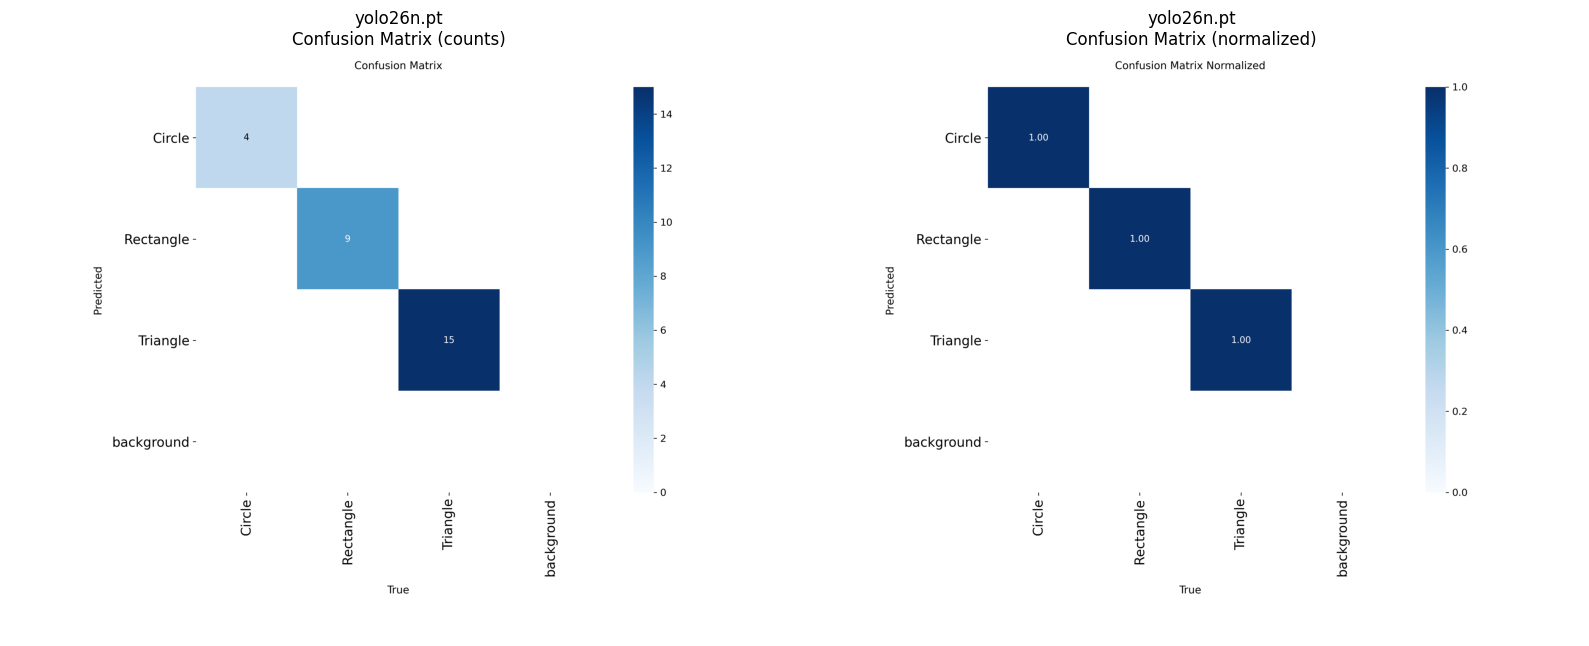

In [15]:
import matplotlib.image as mpimg
import os

test_results = {}

for weights, model in trained_models.items():
    print(f"\n{'='*60}\nTest-set evaluation: {weights}\n{'='*60}")
    metrics = model.val(data=f"{dataset.location}/data.yaml", split="test")
    test_results[weights] = metrics

print(f"\n{'Model':<15}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}")
for weights, metrics in test_results.items():
    print(f"{weights:<15}{metrics.box.map50:<10.3f}{metrics.box.map:<12.3f}"
          f"{metrics.box.mp:<12.3f}{metrics.box.mr:<10.3f}")

for weights, metrics in test_results.items():
    save_dir = str(metrics.save_dir)
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    panels = [
        ("confusion_matrix.png", "Confusion Matrix (counts)"),
        ("confusion_matrix_normalized.png", "Confusion Matrix (normalized)"),
    ]
    for ax, (fname, title) in zip(axes, panels):
        img_path = os.path.join(save_dir, fname)
        if os.path.exists(img_path):
            ax.imshow(mpimg.imread(img_path))
            ax.set_title(f"{weights}\n{title}")
        else:
            ax.set_title(f"{weights}\n{title}\n(not found)")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [21]:
import glob, os

for split in ["train", "valid", "test"]:
    label_files = glob.glob(f"{split}/labels/*.txt")
    empty = [f for f in label_files if os.path.getsize(f) == 0]
    print(f"{split}: {len(empty)}/{len(label_files)} label files are empty")

train: 4/57 label files are empty
valid: 0/0 label files are empty
test: 0/7 label files are empty
